# Predicting Staff Absenteeism at Health Facilities in Sub-Saharan Africa

**Mission:** improve access to healthcare in sub-Saharan Africa so fewer people lose their lives because they cannot reach working health services.

**Use case.** A patient who travels to a clinic gains nothing if the staff are not there. This notebook predicts a facility's **absence rate** (the share of sampled health workers who were absent during an unannounced visit, a number between 0 and 1) from basic facility characteristics.

* **Who would use it:** a health-district manager, a referral coordinator or the operator of a patient-access platform.
* **What for:** to flag facilities that should be verified by phone or visit before patients are routed there, and to show a reliability warning in a facility directory. It is a *risk indicator*, not a real-time availability check.

**Data:** World Bank *Service Delivery Indicators* (SDI) health-facility surveys: real, de-identified data from ten survey rounds across nine African countries (2010-2016); nine rounds have complete equipment data and are used for modelling. Source: the World Bank **SDI-Health** project <https://worldbank.github.io/SDI-Health/> (harmonized data and code: <https://github.com/worldbank/SDI-Health>; programme background: <https://www.sdindicators.org/>). We use two harmonized files: `SDI_AllCountries_Absenteeism.csv` (the target) and `SDI_AllCountries_Facility.csv` (the predictors).

**Notebook map:** facility-level table, cleaning and feature engineering, exploratory plots, split and preprocessing, four tuned models, comparison and best model, required scatter plots, feature importance, saving the model and predicting one row, answers to the assignment questions.

In [1]:
import warnings, copy
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

## 1. Load the data
Two files: one row per **provider** (absenteeism) and one row per **facility** (equipment and characteristics).

In [2]:
DATA_DIR = Path("data")
absent = pd.read_csv(DATA_DIR / "SDI_AllCountries_Absenteeism.csv", low_memory=False)
facility = pd.read_csv(DATA_DIR / "SDI_AllCountries_Facility.csv", low_memory=False)
print("Absenteeism file (one row per PROVIDER):", absent.shape)
print("Facility file    (one row per FACILITY):", facility.shape)

Absenteeism file (one row per PROVIDER): (47654, 44)
Facility file    (one row per FACILITY): (5230, 347)


## 2. Build one row per facility (avoids duplicate-target leakage)
The absenteeism file lists every surveyed provider, but `absence_rate` is a **facility-level** number repeated on each provider row. If we modelled provider rows directly, the same target value would appear in both the train and test sets and make the test score look better than it is. We therefore keep **one row per `country + facility_id`**, check that the target really is constant within a facility, and join the facility characteristics. We never impute the target.

In [3]:
KEY = ["country", "facility_id"]

per_facility = absent.groupby(KEY)["absence_rate"].agg(["first", "nunique"])
print("Unique facilities in the absenteeism file          :", len(per_facility))
print("Median provider rows per facility                   :", int(absent.groupby(KEY).size().median()))
print("Facilities with >1 distinct absence_rate value      :", int((per_facility["nunique"] > 1).sum()))

# One target value per facility. The target is never imputed: facilities without it are removed.
target = per_facility["first"].rename("absence_rate").reset_index().dropna(subset=["absence_rate"])
print("Facilities with a usable target                     :", len(target))

data = target.merge(facility, on=KEY, how="inner")
print("After joining facility characteristics (rows, cols) :", data.shape)

Unique facilities in the absenteeism file          : 5221
Median provider rows per facility                   : 4
Facilities with >1 distinct absence_rate value      : 0
Facilities with a usable target                     : 5201
After joining facility characteristics (rows, cols) : (5201, 348)


## 3. Select features and convert labels to numbers
We keep 10 inputs that are known *before* a visit, have good coverage, and are simple enough for a 10-field mobile form: 4 categorical (country-survey, facility level, public/private, rural/urban) and 6 yes/no availability indicators (auto-disable syringes, disposable syringes, refrigerator, gloves, sharps container, vaccine carrier). The indicators are converted to **1 = available/working, 0 = not available/not functioning**.

In [4]:
CAT_COLS = ["country", "facility_level", "publicprivate", "ruralurban"]
BIN_COLS = ["has_autosyringe", "has_dispsyringe", "has_fridge", "has_gloves", "has_sharps", "has_vaccarrier"]
TARGET = "absence_rate"

def to_binary(value):
    """1 = item available / working ('Yes', 'Yes (Observed)', 'Yes (Not Observed)'); 0 = 'No', 'Not available', 'Not functioning'."""
    if pd.isna(value):
        return np.nan
    return 1.0 if str(value).startswith("Yes") else 0.0

df = data[CAT_COLS].copy()
for col in BIN_COLS:
    df[col] = data[col].map(to_binary)
df[TARGET] = data[TARGET].values

print("Raw labels before conversion to 0/1:")
for col in ["has_fridge", "has_autosyringe"]:
    print(f"  {col}: {data[col].value_counts(dropna=False).to_dict()}")
print("\nMissing values per column (only columns with gaps):")
print(df.isna().sum()[lambda s: s > 0])

Raw labels before conversion to 0/1:
  has_fridge: {'Yes (Observed)': 2459, 'Not available': 1699, nan: 897, 'Yes (Not Observed)': 109, 'Not functioning': 37}
  has_autosyringe: {'Yes (Observed)': 3523, nan: 943, 'No': 552, 'Yes (Not Observed)': 183}

Missing values per column (only columns with gaps):
facility_level     108
publicprivate        4
ruralurban           2
has_autosyringe    943
has_dispsyringe    943
has_fridge         897
has_gloves         157
has_sharps         946
has_vaccarrier     944
dtype: int64


## 4. Handle missing values
Missingness is *structural*: some surveys never asked about certain items (for example the 2010 Senegal survey has no value at all for any of the six equipment items). Imputing whole survey-rounds would invent data, and the API needs every input anyway, so we keep **complete cases only**. The cost is that Senegal-2010 disappears and Niger-2015 shrinks (shown below); this is documented in the README.

In [5]:
rows_before = len(df)
df = df.dropna().reset_index(drop=True)
print(f"Kept {len(df):,} of {rows_before:,} facilities that have all 10 inputs ({rows_before - len(df):,} removed).")

print("\nFacilities per country-survey, before vs after removing incomplete rows:")
pd.concat([data["country"].value_counts().rename("before"),
           df["country"].value_counts().rename("after")], axis=1).fillna(0).astype(int)

Kept 3,942 of 5,201 facilities that have all 10 inputs (1,259 removed).

Facilities per country-survey, before vs after removing incomplete rows:


,before,after
country,,
Nigeria-2013,2471,2164
Madagascar-2016,459,248
Tanzania-2014,401,305
Tanzania-2016,398,313
Uganda-2013,393,244
Kenya-2012,288,253
Niger-2015,256,90
Mozambique-2014,204,193
Togo-2013,180,132


## 5. Feature engineering
We add one numeric feature, **`readiness_count`** = how many of the 6 basic items a facility has (0 to 6). The same function is used by the API, so training and prediction stay consistent. The cleaned table is saved to `../API/facility_training.csv`; the `/retrain` endpoint needs it.

In [6]:
def add_readiness(frame):
    """Numeric feature: how many of the 6 basic items the facility has (0-6). The API uses the same logic."""
    frame = frame.copy()
    frame["readiness_count"] = frame[BIN_COLS].sum(axis=1)
    return frame

df = add_readiness(df)
NUM_COLS = BIN_COLS + ["readiness_count"]
FEATURES = CAT_COLS + NUM_COLS
print("Categorical features (4):", CAT_COLS)
print("Numeric features    (7):", NUM_COLS)
print("Rows:", len(df), "| feature columns:", len(FEATURES))

# Cleaned table (one row per facility: 10 inputs + target) reused by the API's /retrain endpoint.
Path("../API").mkdir(exist_ok=True)
clean = df[CAT_COLS + BIN_COLS + [TARGET]].copy()
clean[BIN_COLS] = clean[BIN_COLS].astype(int)
clean.to_csv("../API/facility_training.csv", index=False)
df.head()

Categorical features (4): ['country', 'facility_level', 'publicprivate', 'ruralurban']
Numeric features    (7): ['has_autosyringe', 'has_dispsyringe', 'has_fridge', 'has_gloves', 'has_sharps', 'has_vaccarrier', 'readiness_count']
Rows: 3942 | feature columns: 11


,country,facility_level,publicprivate,ruralurban,has_autosyringe,has_dispsyringe,has_fridge,has_gloves,has_sharps,has_vaccarrier,absence_rate,readiness_count
0,Kenya-2012,Health Post,Private,Rural,0.0,1.0,1.0,1.0,1.0,1.0,0.0,5.0
1,Kenya-2012,Health Center,Public,Rural,1.0,1.0,1.0,1.0,1.0,1.0,0.7,6.0
2,Kenya-2012,Health Post,Private,Rural,1.0,1.0,1.0,1.0,1.0,1.0,0.5,6.0
3,Kenya-2012,Hospital,Public,Rural,1.0,1.0,1.0,1.0,1.0,1.0,0.5,6.0
4,Kenya-2012,Health Post,Public,Rural,1.0,1.0,1.0,1.0,1.0,1.0,0.4,6.0


### Columns dropped, and why

| Dropped | Reason |
|---|---|
| `provider_present1/2/3`, `has_absentee`, `absence_rate2`, `absent_*`, roster counts | **Target leakage**: `absence_rate` is calculated from them (`1 - present / surveyed`). |
| `survey_id`, `unique_id`, `provider_id`, `facility_id`, `countrycode` | Identifiers, not predictors. |
| `abs_wt`, `ipw`, `final_wt`, `*_fpc`, `*_prob`, other `*_wt` | Survey weights / sampling probabilities, not facility characteristics. |
| `admin1` ... `admin6` | Codes that mean different regions in different countries (code 5 in Kenya is not code 5 in Nigeria); `admin1` also has ~9% missing. |
| `has_weights` | Only one value (1) and otherwise missing, so it carries no information. |
| `num_outpatient`, `num_births`, `num_med`, `num_nonmed` | Stored as bands such as "0-500" or "5 or less", so they are not continuous and are mostly missing. |
| ~300 other facility columns (individual drugs, equipment, waste handling, ...) | Mostly specific to one survey round, so they are very sparse; including them would also make a mobile form impractical. |
| Senegal-2010 rows | Removed by the complete-case rule above, because the survey did not collect those items. |

**Which features matter most for the target?** Answered with data in section 11: the country-survey and the facility level matter far more than any equipment indicator.

In [7]:
df[[TARGET] + NUM_COLS].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
absence_rate,3942.0,0.400,0.312,0.0,0.0,0.4,0.6,1.0
has_autosyringe,3942.0,0.881,0.324,0.0,1.0,1.0,1.0,1.0
has_dispsyringe,3942.0,0.936,0.246,0.0,1.0,1.0,1.0,1.0
has_fridge,3942.0,0.607,0.488,0.0,0.0,1.0,1.0,1.0
has_gloves,3942.0,0.855,0.353,0.0,1.0,1.0,1.0,1.0
has_sharps,3942.0,0.948,0.223,0.0,1.0,1.0,1.0,1.0
has_vaccarrier,3942.0,0.957,0.202,0.0,1.0,1.0,1.0,1.0
readiness_count,3942.0,5.183,1.044,0.0,5.0,5.0,6.0,6.0


## 6. Exploratory data analysis
Four plots, each followed by what it shows and what we decided because of it.

Facilities with absence_rate exactly 0: 25.6%
Mean = 0.400, median = 0.400, std = 0.312


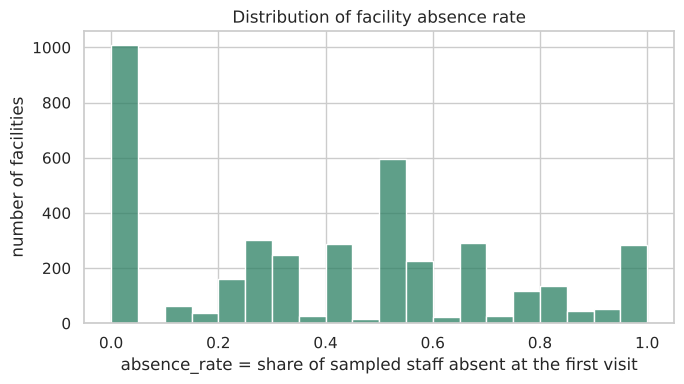

In [8]:
share_zero = (df[TARGET] == 0).mean()
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df[TARGET], bins=20, ax=ax, color="#2a7f62")
ax.set_title("Distribution of facility absence rate")
ax.set_xlabel("absence_rate = share of sampled staff absent at the first visit")
ax.set_ylabel("number of facilities")
plt.tight_layout(); plt.show()
print(f"Facilities with absence_rate exactly 0: {share_zero:.1%}")
print(f"Mean = {df[TARGET].mean():.3f}, median = {df[TARGET].median():.3f}, std = {df[TARGET].std():.3f}")

**What it shows.** The target is bounded between 0 and 1 and takes only a few dozen distinct values because it is a fraction of a small staff sample. About a quarter of facilities (25.6%) have an absence rate of exactly 0, followed by peaks around 0.25 to 0.5. **Decision:** keep the zeros (they are real "nobody was absent" visits), evaluate with MSE as required, and expect a modest score because the distribution is spiky and zero-inflated.

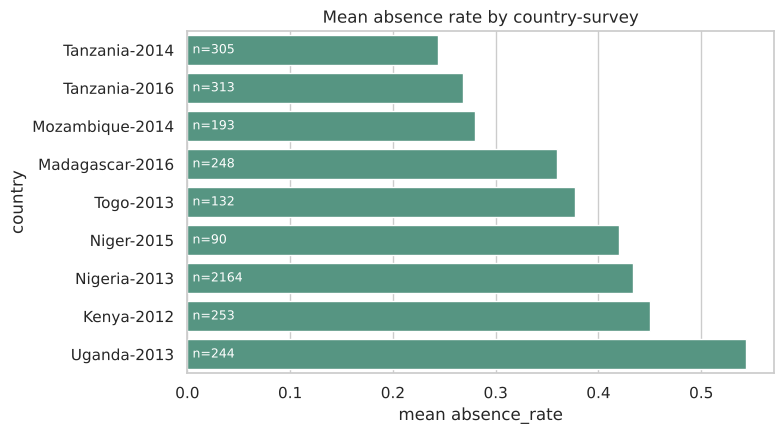

,count,mean,median
country,,,
Tanzania-2014,305,0.244,0.250
Tanzania-2016,313,0.268,0.300
Mozambique-2014,193,0.280,0.273
Madagascar-2016,248,0.360,0.333
Togo-2013,132,0.377,0.333
Niger-2015,90,0.420,0.477
Nigeria-2013,2164,0.434,0.500
Kenya-2012,253,0.450,0.500
Uganda-2013,244,0.544,0.563


In [9]:
order = df.groupby("country")[TARGET].mean().sort_values().index
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=df, y="country", x=TARGET, order=order, errorbar=None, color="#4c9f86", ax=ax)
for i, c in enumerate(order):
    n = (df["country"] == c).sum()
    ax.text(0.005, i, f"n={n}", va="center", color="white", fontsize=9)
ax.set_title("Mean absence rate by country-survey")
ax.set_xlabel("mean absence_rate")
plt.tight_layout(); plt.show()
df.groupby("country")[TARGET].agg(["count", "mean", "median"]).round(3).sort_values("mean")

**What it shows.** Average absence differs a lot by country-survey, from about 0.24 (Tanzania-2014) to 0.54 (Uganda-2013). Nigeria-2013 is also 55% of all rows. **Decision:** keep `country` as a categorical feature (one-hot encoded) because it carries real signal, and use a stratified split so every country appears in both train and test. We must also remember that the model reflects Nigeria most strongly.

Correlation with the target (sorted by absolute value):


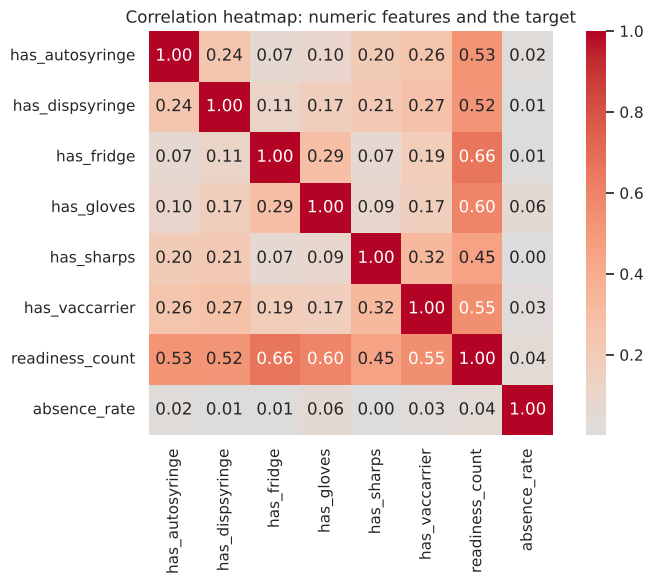

has_gloves         0.061
readiness_count    0.041
has_vaccarrier     0.027
has_autosyringe    0.024
has_fridge         0.011
has_dispsyringe    0.008
has_sharps         0.001
Name: absence_rate, dtype: float64

In [10]:
corr = df[NUM_COLS + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Correlation heatmap: numeric features and the target")
plt.tight_layout(); plt.show()
print("Correlation with the target (sorted by absolute value):")
corr[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False).round(3)

**What it shows.** Every numeric feature is only very weakly correlated with the target (the largest is `has_gloves`, r = 0.06). `readiness_count` correlates 0.45 to 0.66 with its own components because it is their sum. **Decision:** no single equipment item will be a strong predictor, so we do not expect a high R-squared. We keep `readiness_count` because the assignment needs a numeric feature and it is cheap, but note that it is an exact linear combination of the six indicators, so individual coefficients of the linear models should not be over-interpreted.

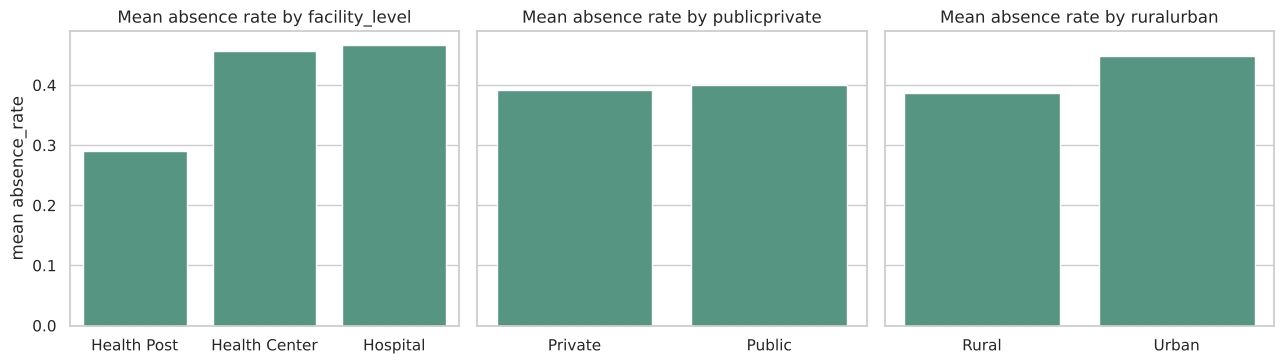

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, col in zip(axes, ["facility_level", "publicprivate", "ruralurban"]):
    sns.barplot(data=df, x=col, y=TARGET, errorbar=None, color="#4c9f86", ax=ax)
    ax.set_title(f"Mean absence rate by {col}")
    ax.set_xlabel("")
axes[0].set_ylabel("mean absence_rate")
plt.tight_layout(); plt.show()

**What it shows.** Health Posts have a clearly lower mean absence rate (0.29) than Health Centers (0.46) and Hospitals (0.47), and urban facilities are a bit higher than rural ones (0.45 vs 0.39). Public and private facilities are almost identical (0.40 vs 0.39). **Decision:** keep `facility_level` and `ruralurban`; `publicprivate` is kept for completeness but is expected to add little.

## 7. Train/test split and preprocessing
* 80% / 20% split, stratified by country, `random_state=42`.
* Categorical columns are one-hot encoded; numeric columns are standardized.
* The encoder and scaler are **fitted on the training set only** and then applied to the test set, so no test information leaks into training.

In [12]:
X = df[FEATURES]
y = df[TARGET].values

# Facility-level table => one row per facility, so a random split cannot put the same target in train and test.
# Stratifying by country keeps the country mix similar in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=df["country"])
print("Train:", X_train.shape, "| Test:", X_test.shape)

def make_preprocessor():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),   # categorical -> numeric
        ("num", StandardScaler(), NUM_COLS),                                              # standardize numeric
    ])

preprocessor = make_preprocessor()
preprocessor.fit(X_train)                      # encoder and scaler are fitted on the TRAINING set only
X_train_p = preprocessor.transform(X_train)
X_test_p = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()
print("Model matrix after encoding + scaling:", X_train_p.shape, "->", len(feature_names), "columns")
print("Mean of scaled numeric columns on TRAIN (should be ~0):", np.round(X_train_p[:, -len(NUM_COLS):].mean(axis=0), 3))
print("Mean of the same columns on TEST (not exactly 0, as expected):", np.round(X_test_p[:, -len(NUM_COLS):].mean(axis=0), 3))

Train: (3153, 11) | Test: (789, 11)
Model matrix after encoding + scaling: (3153, 23) -> 23 columns
Mean of scaled numeric columns on TRAIN (should be ~0): [-0.  0.  0. -0.  0. -0. -0.]
Mean of the same columns on TEST (not exactly 0, as expected): [-0.058  0.005  0.048  0.012  0.009 -0.059  0.001]


The scaled training columns have mean 0 (as they must), while the test columns are close to but not exactly 0, which confirms the scaler was fitted on the training data only. The matrix has 23 columns: 9 countries + 3 facility levels + 2 + 2 one-hot columns, plus 7 numeric ones.

## 8. Train and compare four scikit-learn models
All four are evaluated on the **same test set** with mean squared error (MSE). Settings are chosen **without looking at the test set**: SGD uses a validation split taken from the training data, and the tree and forest use cross-validation on the training data.

### 8.1 SGDRegressor: linear regression by gradient descent (tuned)
We tune three things: the **learning rate** (`eta0`), the **L2 regularization strength** (`alpha`) and the **number of epochs**. scikit-learn does not store loss per epoch, so we train with `partial_fit` in a loop (one `partial_fit` call = one epoch) and record the loss after every epoch.

In [13]:
def mse(a, b):
    return mean_squared_error(a, b)

# Tuning uses a validation split carved out of the TRAINING data, so the test set is never used to choose settings.
Xa, Xv, ya, yv = train_test_split(X_train_p, y_train, test_size=0.2, random_state=RANDOM_STATE)

def sgd_curve(eta0, alpha, epochs, Xtr, ytr, Xev, yev):
    """Gradient descent one epoch at a time with partial_fit, storing train and evaluation MSE after every epoch."""
    model = SGDRegressor(loss="squared_error", penalty="l2", alpha=alpha,
                         learning_rate="constant", eta0=eta0, random_state=RANDOM_STATE)
    tr, ev = [], []
    for _ in range(epochs):
        model.partial_fit(Xtr, ytr)
        tr.append(mse(ytr, model.predict(Xtr)))
        ev.append(mse(yev, model.predict(Xev)))
    return np.array(tr), np.array(ev)

ETAS = [0.0001, 0.001, 0.01, 0.05]            # learning rates
ALPHAS = [0.0, 1e-5, 1e-4, 1e-3, 1e-2]       # L2 regularization strengths
MAX_EPOCHS = 200                              # numbers of epochs (we record every epoch and pick the best)

curves, rows = {}, []
for eta0 in ETAS:
    for alpha in ALPHAS:
        tr, va = sgd_curve(eta0, alpha, MAX_EPOCHS, Xa, ya, Xv, yv)
        curves[(eta0, alpha)] = (tr, va)
        rows.append({"eta0": eta0, "alpha": alpha, "best_epoch": int(va.argmin()) + 1,
                     "best_val_mse": va.min(), f"val_mse_at_{MAX_EPOCHS}": va[-1]})

grid = pd.DataFrame(rows).sort_values("best_val_mse").reset_index(drop=True)
best = grid.iloc[0]
best_eta0, best_alpha, best_epochs = float(best["eta0"]), float(best["alpha"]), int(best["best_epoch"])
print(f"Best SGD setting on the validation split: eta0={best_eta0}, alpha={best_alpha}, epochs={best_epochs}")
grid.round(5).head(12)

Best SGD setting on the validation split: eta0=0.0001, alpha=0.0, epochs=108


,eta0,alpha,best_epoch,best_val_mse,val_mse_at_200
0,0.0001,0.00000,108,0.08386,0.08395
1,0.0001,0.00001,108,0.08386,0.08395
2,0.0001,0.00010,108,0.08386,0.08395
3,0.0001,0.00100,110,0.08387,0.08395
4,0.0001,0.01000,146,0.08398,0.08399
5,0.0010,0.00000,11,0.08407,0.08423
6,0.0010,0.00001,11,0.08407,0.08423
7,0.0010,0.00010,11,0.08407,0.08423
8,0.0010,0.00100,11,0.08408,0.08422
9,0.0010,0.01000,14,0.08417,0.08418


Best validation MSE for each learning rate (best alpha/epoch for that rate):
eta0
0.0001    0.08386
0.0010    0.08407
0.0100    0.08561
0.0500    0.63500

Best validation MSE for each alpha (best learning rate/epoch for that alpha):
alpha
0.00000    0.08386
0.00001    0.08386
0.00010    0.08386
0.00100    0.08387
0.01000    0.08398


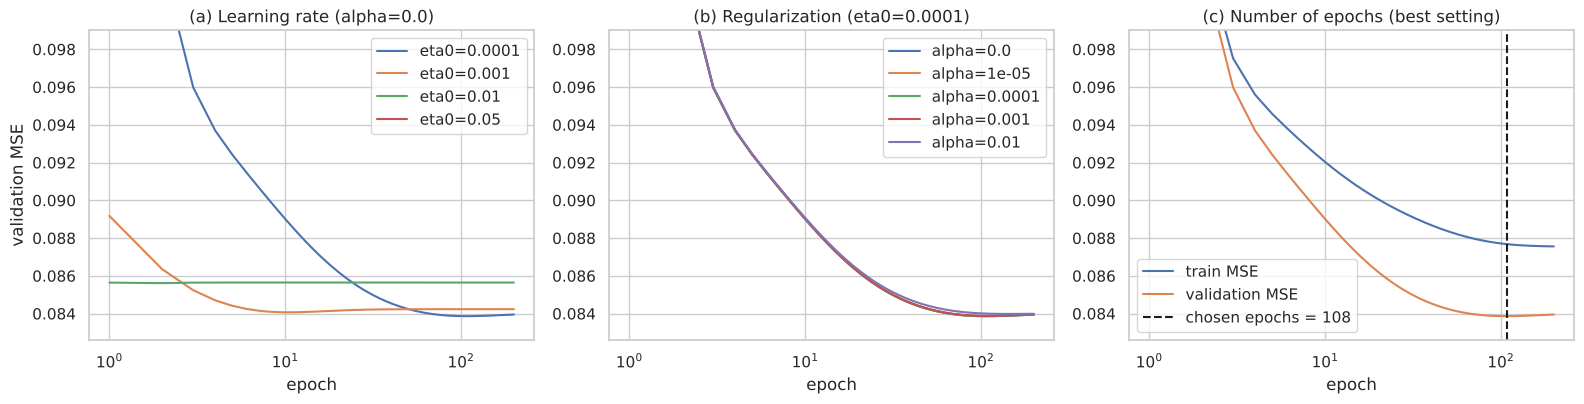

In [14]:
baseline_val = np.var(yv)                                   # MSE of always predicting the mean
lo, hi = grid["best_val_mse"].min() * 0.985, baseline_val * 1.02
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

for eta0 in ETAS:                                           # (a) learning rate, alpha fixed at the best value
    axes[0].plot(range(1, MAX_EPOCHS + 1), curves[(eta0, best_alpha)][1], label=f"eta0={eta0}")
axes[0].set(title=f"(a) Learning rate (alpha={best_alpha})", xlabel="epoch", ylabel="validation MSE", ylim=(lo, hi), xscale="log")
axes[0].legend()

for alpha in ALPHAS:                                        # (b) regularization strength, learning rate fixed
    axes[1].plot(range(1, MAX_EPOCHS + 1), curves[(best_eta0, alpha)][1], label=f"alpha={alpha}")
axes[1].set(title=f"(b) Regularization (eta0={best_eta0})", xlabel="epoch", ylim=(lo, hi), xscale="log")
axes[1].legend()

tr, va = curves[(best_eta0, best_alpha)]                    # (c) number of epochs for the best setting
axes[2].plot(range(1, MAX_EPOCHS + 1), tr, label="train MSE")
axes[2].plot(range(1, MAX_EPOCHS + 1), va, label="validation MSE")
axes[2].axvline(best_epochs, color="k", ls="--", label=f"chosen epochs = {best_epochs}")
axes[2].set(title="(c) Number of epochs (best setting)", xlabel="epoch", ylim=(lo, hi), xscale="log")
axes[2].legend()
plt.tight_layout(); plt.show()

print("Best validation MSE for each learning rate (best alpha/epoch for that rate):")
print(grid.groupby("eta0")["best_val_mse"].min().round(5).to_string())
print("\nBest validation MSE for each alpha (best learning rate/epoch for that alpha):")
print(grid.groupby("alpha")["best_val_mse"].min().round(5).to_string())

**What the tuning shows.**
* **Learning rate:** `eta0=0.0001` reached the lowest validation MSE (0.08386) but needs about 108 epochs; `0.001` needs about 11 epochs and is slightly worse (0.08407); `0.01` converges in 2 epochs but stops higher (0.08561); `0.05` **diverges** (MSE about 0.63) because the steps are too large, so its curve is off the chart.
* **Regularization (`alpha`):** values from 0 to 1e-4 give identical results, 1e-3 is the same to four decimals, and 1e-2 is slightly worse (0.08398). With only 23 inputs and about 2,500 training rows the model barely overfits, so regularization has almost nothing to fix; a stronger penalty simply shrinks the weights a little too much.
* **Epochs:** the validation loss falls quickly, then flattens; the best point for the chosen setting is epoch 108, and training longer does not help.

At the chosen epoch (108): train MSE = 0.0868, test MSE = 0.0826


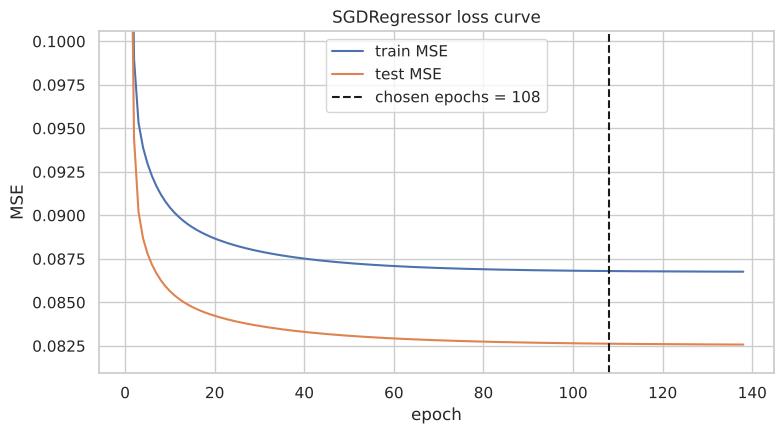

In [15]:
# Final SGD run on the full training set with the chosen setting; record train AND test MSE after every epoch.
EPOCHS_TO_PLOT = max(100, best_epochs + 30)
sgd = SGDRegressor(loss="squared_error", penalty="l2", alpha=best_alpha,
                   learning_rate="constant", eta0=best_eta0, random_state=RANDOM_STATE)
train_hist, test_hist = [], []
sgd_final = None
for epoch in range(1, EPOCHS_TO_PLOT + 1):
    sgd.partial_fit(X_train_p, y_train)
    train_hist.append(mse(y_train, sgd.predict(X_train_p)))
    test_hist.append(mse(y_test, sgd.predict(X_test_p)))
    if epoch == best_epochs:
        sgd_final = copy.deepcopy(sgd)          # the model we keep = state after the chosen number of epochs

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, EPOCHS_TO_PLOT + 1), train_hist, label="train MSE")
ax.plot(range(1, EPOCHS_TO_PLOT + 1), test_hist, label="test MSE")
ax.axvline(best_epochs, color="k", ls="--", label=f"chosen epochs = {best_epochs}")
ax.set(title="SGDRegressor loss curve", xlabel="epoch", ylabel="MSE")
ax.set_ylim(min(train_hist + test_hist) * 0.98, np.var(y_train) * 1.02)
ax.legend(); plt.tight_layout(); plt.show()
print(f"At the chosen epoch ({best_epochs}): train MSE = {train_hist[best_epochs-1]:.4f}, test MSE = {test_hist[best_epochs-1]:.4f}")

**Loss curve (required plot).** Train and test MSE fall together and flatten; they never diverge, so there is **no overfitting**. At the chosen 108 epochs the train MSE is 0.0868 and the test MSE is 0.0826. The test loss is a little lower than the training loss simply because this particular test split is slightly easier; it is not a sign of leakage. The plateau means gradient descent has converged to the same least-squares solution that the closed-form model finds directly.

### 8.2 to 8.4 Closed-form linear regression, decision tree, random forest
`LinearRegression` has no hyperparameters. The decision tree is tuned over `max_depth` and `min_samples_leaf`, and the random forest over `n_estimators`, `max_depth` and `min_samples_leaf` (kept small so the saved model is light enough for a free Render server).

In [16]:
# 2) Linear regression, closed form
lin = LinearRegression().fit(X_train_p, y_train)

# 3) Decision tree (depth / leaf size tuned with 5-fold CV on the training set)
tree_cv = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    {"max_depth": [3, 5, 7, 10, None], "min_samples_leaf": [5, 10, 20, 50]},
    scoring="neg_mean_squared_error", cv=5, n_jobs=-1).fit(X_train_p, y_train)

# 4) Random forest (kept small so the saved file stays light for deployment)
rf_cv = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    {"n_estimators": [100, 200], "max_depth": [8, 12], "min_samples_leaf": [5, 10, 20]},
    scoring="neg_mean_squared_error", cv=3, n_jobs=1).fit(X_train_p, y_train)

print("Best decision tree settings :", tree_cv.best_params_)
print("Best random forest settings :", rf_cv.best_params_)

Best decision tree settings : {'max_depth': 5, 'min_samples_leaf': 20}
Best random forest settings : {'max_depth': 12, 'min_samples_leaf': 20, 'n_estimators': 200}


## 9. Compare the four models and choose the best
Train MSE and test MSE for every model (lower is better). `test_rmse` and `test_r2` are added for interpretation.

In [17]:
fitted = {
    "SGDRegressor (gradient descent)": sgd_final,
    "LinearRegression (closed form)": lin,
    "DecisionTreeRegressor": tree_cv.best_estimator_,
    "RandomForestRegressor": rf_cv.best_estimator_,
}
rows = []
for name, est in fitted.items():
    p_tr, p_te = est.predict(X_train_p), est.predict(X_test_p)
    rows.append({"model": name, "train_mse": mse(y_train, p_tr), "test_mse": mse(y_test, p_te),
                 "test_rmse": np.sqrt(mse(y_test, p_te)), "test_r2": r2_score(y_test, p_te)})
results = pd.DataFrame(rows).set_index("model")

baseline_test = mse(y_test, np.full_like(y_test, y_train.mean()))
best_name = results["test_mse"].idxmin()
print(f"Reference: always predicting the training mean gives test MSE = {baseline_test:.4f}")
print(f"BEST MODEL (lowest test MSE): {best_name}  ->  test MSE = {results.loc[best_name, 'test_mse']:.4f}")
results.round(5)

Reference: always predicting the training mean gives test MSE = 0.0932
BEST MODEL (lowest test MSE): LinearRegression (closed form)  ->  test MSE = 0.0826


,train_mse,test_mse,test_rmse,test_r2
model,,,,
SGDRegressor (gradient descent),0.08680,0.08262,0.28744,0.11221
LinearRegression (closed form),0.08674,0.08262,0.28744,0.11223
DecisionTreeRegressor,0.08672,0.08438,0.29049,0.09332
RandomForestRegressor,0.08501,0.08304,0.28817,0.10773


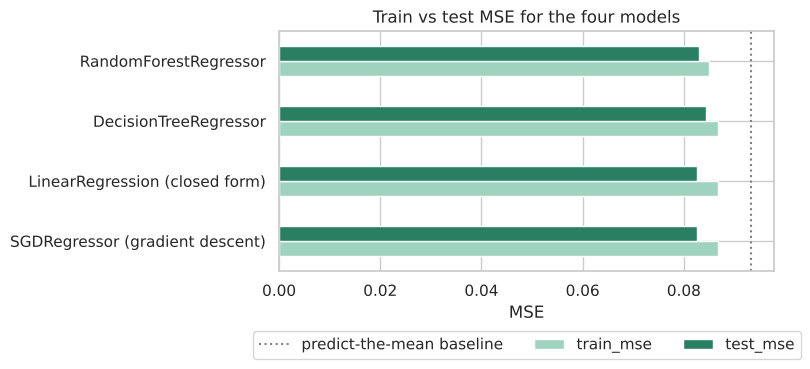

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
results[["train_mse", "test_mse"]].plot.barh(ax=ax, color=["#9fd3c0", "#2a7f62"])
ax.axvline(baseline_test, color="grey", ls=":", label="predict-the-mean baseline")
ax.set_xlabel("MSE"); ax.set_ylabel(""); ax.set_title("Train vs test MSE for the four models")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3); plt.tight_layout(); plt.show()

**Best model = lowest test MSE = `LinearRegression` (closed form), test MSE 0.08262.** `SGDRegressor` is level with it to four decimals (0.08262, 0.00002 R-squared behind), the random forest is slightly worse (0.08304) and the decision tree is the worst (0.08438). All four beat the predict-the-mean baseline (0.0932).

**Why the dataset leads to this ranking.** The inputs are mostly yes/no equipment flags with almost no variation (e.g. 95% of facilities have sharps containers) and the target is dominated by two categorical effects (country and facility type) plus a lot of unexplained noise. That is a mostly *additive* signal, which a linear model captures fully; the tree and forest have no strong interactions to find, so they only add variance. The forest fits the training data slightly better than the linear model (train MSE 0.0850 vs 0.0867) but does slightly worse on unseen data (0.0830 vs 0.0826), which is the small sign of extra variance. **Justification for the choice:** the simplest model that is as accurate as, or better than, the complex ones is also the fastest to retrain, the smallest to deploy (the saved file is a few KB) and the easiest to explain to a health-district manager.

## 10. Required scatter plots: most correlated feature vs target
The feature most correlated with the target (among the numeric features, measured on the training set) is plotted against the target first, then again with a one-feature linear regression line fitted for this plot only. A tiny horizontal jitter separates the overlapping points because the feature only takes the values 0 and 1.

Most correlated numeric feature: has_gloves (r = 0.062)


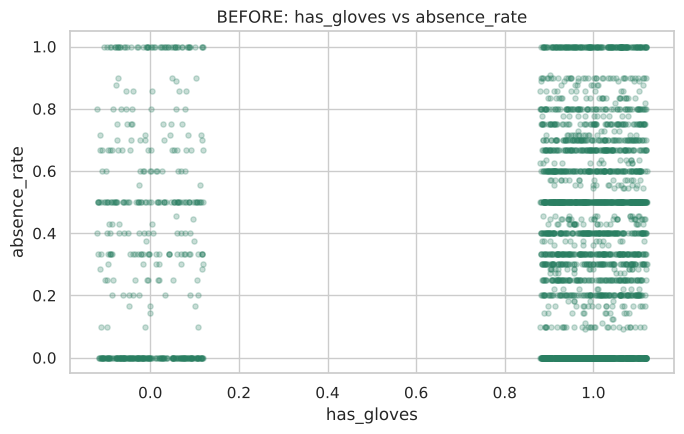

In [19]:
# Feature most correlated with the target (numeric features, training set)
train_df = X_train.copy(); train_df[TARGET] = y_train
corr_train = train_df[NUM_COLS + [TARGET]].corr()[TARGET].drop(TARGET)
top_feature = corr_train.abs().idxmax()
print(f"Most correlated numeric feature: {top_feature} (r = {corr_train[top_feature]:.3f})")

rng = np.random.default_rng(RANDOM_STATE)
x_vals = train_df[top_feature].values
jitter = rng.uniform(-0.12, 0.12, size=len(x_vals))   # small horizontal jitter: the feature takes few distinct values

# BEFORE: scatter only
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(x_vals + jitter, y_train, alpha=0.25, s=14, color="#2a7f62")
ax.set(title=f"BEFORE: {top_feature} vs absence_rate", xlabel=top_feature, ylabel=TARGET)
plt.tight_layout(); plt.show()

One-feature line: slope = 0.0555, intercept = 0.3501


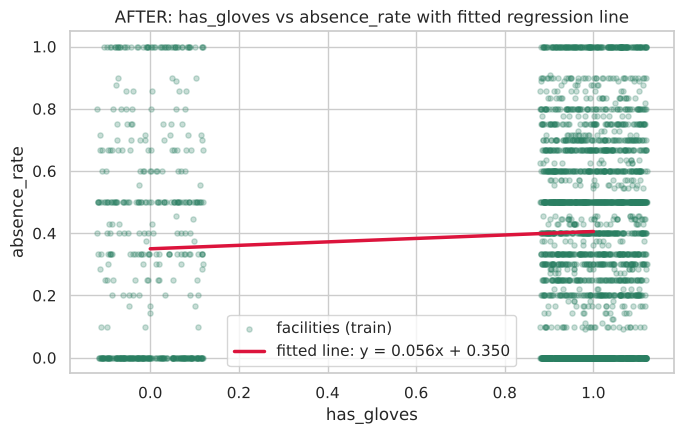

In [20]:
# AFTER: same scatter + a one-feature linear regression line (fitted for this plot only)
line_model = LinearRegression().fit(x_vals.reshape(-1, 1), y_train)
xs = np.linspace(x_vals.min(), x_vals.max(), 50).reshape(-1, 1)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(x_vals + jitter, y_train, alpha=0.25, s=14, color="#2a7f62", label="facilities (train)")
ax.plot(xs, line_model.predict(xs), color="crimson", lw=2.5,
        label=f"fitted line: y = {line_model.coef_[0]:.3f}x + {line_model.intercept_:.3f}")
ax.set(title=f"AFTER: {top_feature} vs absence_rate with fitted regression line", xlabel=top_feature, ylabel=TARGET)
ax.legend(); plt.tight_layout(); plt.show()
print(f"One-feature line: slope = {line_model.coef_[0]:.4f}, intercept = {line_model.intercept_:.4f}")

**What it shows.** The cloud is wide for both values and the fitted line is almost flat: facilities with gloves average about 0.41 versus 0.35 without (slope 0.056). The positive sign does **not** mean gloves cause absence; better equipped facilities tend to be larger health centers and hospitals, which have higher absence rates (see the facility-level plot). This also confirms that no single feature explains the target, which is why the full model mostly relies on country and facility type.

## 11. Which features matter most? (permutation importance)
Each original feature is shuffled on the test set and we measure how much the test MSE gets worse. A bigger increase means the model relies on that feature more.

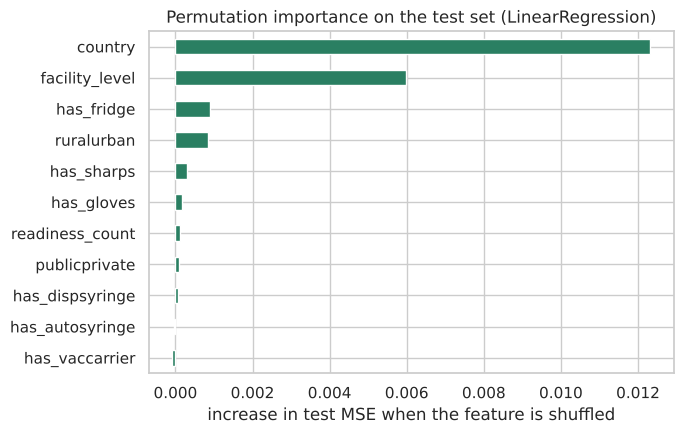

country            0.01231
facility_level     0.00599
has_fridge         0.00089
ruralurban         0.00084
has_sharps         0.00031
has_gloves         0.00016
readiness_count    0.00011
publicprivate      0.00009
has_dispsyringe    0.00007
has_autosyringe   -0.00004
has_vaccarrier    -0.00008
dtype: float64

In [21]:
best_pipeline = Pipeline([("pre", preprocessor), ("model", fitted[best_name])])
assert np.allclose(best_pipeline.predict(X_test), fitted[best_name].predict(X_test_p))

perm = permutation_importance(best_pipeline, X_test, y_test, scoring="neg_mean_squared_error",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)
importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
importance.plot.barh(ax=ax, color="#2a7f62")
ax.set_title(f"Permutation importance on the test set ({best_name.split(' ')[0]})")
ax.set_xlabel("increase in test MSE when the feature is shuffled")
plt.tight_layout(); plt.show()
importance.sort_values(ascending=False).round(5)

**What it shows.** `country` (0.0123) and `facility_level` (0.0060) dominate, followed by a tiny effect from `has_fridge` and `ruralurban` (about 0.0009 each). All other equipment indicators are essentially zero, and a few are slightly negative (shuffling them does not hurt, so they are noise). **Decision/meaning:** for this problem *where* and *what type of facility* matter far more than basic equipment, so more useful extra features would be staffing levels, patient load or management information rather than more equipment checks.

## 12. Save the best model with its preprocessing
The full scikit-learn `Pipeline` (one-hot encoder + scaler + best model) is saved with `joblib`, so the API can predict from raw inputs without re-implementing any preprocessing.

In [22]:
MODEL_PATH = Path("../API/best_model.pkl")
joblib.dump(best_pipeline, MODEL_PATH, compress=3)      # preprocessing + model saved together
print(f"Saved {best_name} pipeline to {MODEL_PATH}  ({MODEL_PATH.stat().st_size / 1024:.0f} KB)")

Saved LinearRegression (closed form) pipeline to ../API/best_model.pkl  (2 KB)


In [23]:
def predict_one_test_row(row_position=0, model_path="../API/best_model.pkl"):
    """Load the saved pipeline and predict the target for ONE row of the test set."""
    model = joblib.load(model_path)
    row = X_test.iloc[[row_position]]                    # one test-set row (11 columns incl. readiness_count)
    predicted = float(np.clip(model.predict(row)[0], 0, 1))
    actual = float(y_test[row_position])
    print("Input row:")
    print(row.T.to_string(header=False))
    print(f"\nPredicted absence rate: {predicted:.3f} ({predicted:.0%})")
    print(f"Actual absence rate   : {actual:.3f} ({actual:.0%})")
    return predicted

_ = predict_one_test_row(0)

Input row:
country          Tanzania-2014
facility_level     Health Post
publicprivate          Private
ruralurban               Rural
has_autosyringe            1.0
has_dispsyringe            1.0
has_fridge                 1.0
has_gloves                 1.0
has_sharps                 1.0
has_vaccarrier             1.0
readiness_count            6.0

Predicted absence rate: 0.182 (18%)
Actual absence rate   : 0.500 (50%)


The function above loads the saved pipeline and predicts the target for one test row. The API (`API/prediction.py`) reuses exactly this logic. For this particular row the model predicts 18% while the real value is 50%, a good reminder that with R-squared around 0.11 the model is a coarse *risk flag*, not a precise forecast.

## 13. Answers to the assignment questions

**1. Is the test loss high or low, and how would you reduce it?**
The test MSE is **0.0826** (RMSE 0.287, i.e. about 29 percentage points of error on a 0 to 1 scale; R-squared 0.11). It beats the predict-the-mean baseline (0.0932) by about 11%, but in absolute terms it is **high**: the typical error is almost as large as the spread of the target itself (std 0.31). To reduce it I would: (a) add genuinely informative features such as staff numbers, patient load, salary delays or management practices instead of more equipment flags; (b) model the zero-inflation explicitly (first predict whether the absence rate is 0, then its size); (c) collect or recover more data for under-represented surveys such as Niger (90 rows) and Senegal (removed); (d) try interactions between country and facility type, or a bounded-response model.

**2. Which hyperparameters did you tune and how did each change the loss?**
*SGD:* learning rate (0.0001 best at 0.0839 validation MSE but slow; 0.001 and 0.01 faster but slightly worse; 0.05 diverges), L2 `alpha` (0 to 1e-4 identical, 1e-2 slightly worse because it shrinks the weights too much) and number of epochs (loss flattens at about 108). *Decision tree:* `max_depth` and `min_samples_leaf` (cross-validation preferred a shallow tree: depth 5, leaf 20). *Random forest:* `n_estimators`, `max_depth`, `min_samples_leaf` (best 200 trees, depth 12, leaf 20).

**3. What happens when new data arrives and how is the deployed model updated?**
Someone uploads a CSV with the same 11 columns as the training data (10 inputs + `absence_rate`) to `POST /retrain`. Because the best model is `LinearRegression` (not SGD), the API **refits the whole pipeline on the original data plus the new rows**, swaps the new model into memory so `/predict` uses it immediately with no redeploy, and saves the new model file and the extended dataset. (If SGD had been best it would continue training with `partial_fit` on the new rows only.) On Render's free plan the saved files are lost when the service restarts, so it reloads the model from the repository at start-up; this is accepted by the assignment.

**4. Why was CORS configured this way?**
The API lists explicit browser origins (its own Render URL and local development addresses) instead of `*`, allows only the methods it uses (GET and POST) and only the headers it needs, and sets `allow_credentials=True`. A wildcard would let any website call the API from a visitor's browser, and browsers refuse `*` together with credentials anyway. A native Flutter mobile app is not a browser, so CORS does not restrict it; the configuration only controls which websites can call the API.

---
### Limitations to state honestly
* Survey data from 2010 to 2016 in 9 country-surveys (Nigeria is 55% of the rows): predictions are not current, GPS-level or real-time.
* The model is correlational, not causal, and explains only about 11% of the variation.
* Complete-case selection removed Senegal-2010 and shrank Niger-2015.